In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from DataAnalysis import generate_correlation_heatmap, corr_test
from DataPreprocessing import smart_imputer

In [3]:
path = "/Users/zuzannasosnowska/.cache/kagglehub/datasets/krzysztofjamroz/apartment-prices-in-poland/versions/9/apartments_pl_2024_06.csv"

df = pd.read_csv(path)

df["price_per_m2"] = df["price"] / df["squareMeters"]

polish_cities_names = {'szczecin': 'Szczecin', 'gdynia': 'Gdynia', 'krakow': 'Kraków',  'poznan': 'Poznań', 'bialystok': 'Białystok',  'gdansk': 'Gdańsk', 'wroclaw': 'Wrocław', 'radom': 'Radom', 'rzeszow': 'Rzeszów', 'lodz': 'Łódź', 'katowice': 'Katowice', 'lublin': 'Lublin', 'czestochowa': 'Częstochowa', 'warszawa': 'Warszawa', 'bydgoszcz': 'Bydgoszcz'}

df['city'] = [polish_cities_names[city] for city in df['city']]

city_dataframes = {city: df[df["city"] == city] for city in df.city.unique()}
cities = df["city"].unique()

df = smart_imputer(df)[0]

In [8]:
categorical_data = ['city', 'type', 'ownership', 'buildingMaterial', 'condition', 'hasParkingSpace', 'hasBalcony', 'hasElevator', 'hasSecurity', 'hasStorageRoom']

both_categorical_and_numeric = ['rooms', 'floor', 'floorCount']

numeric_data = ['squareMeters', 'buildYear', 'latitude', 'longitude', 'centreDistance', 'poiCount', 'schoolDistance', 'clinicDistance', 'postOfficeDistance', 'kindergartenDistance', 'restaurantDistance', 'collegeDistance', 'pharmacyDistance', 'price', 'price_per_m2']

df[categorical_data] = df[categorical_data].astype("category")

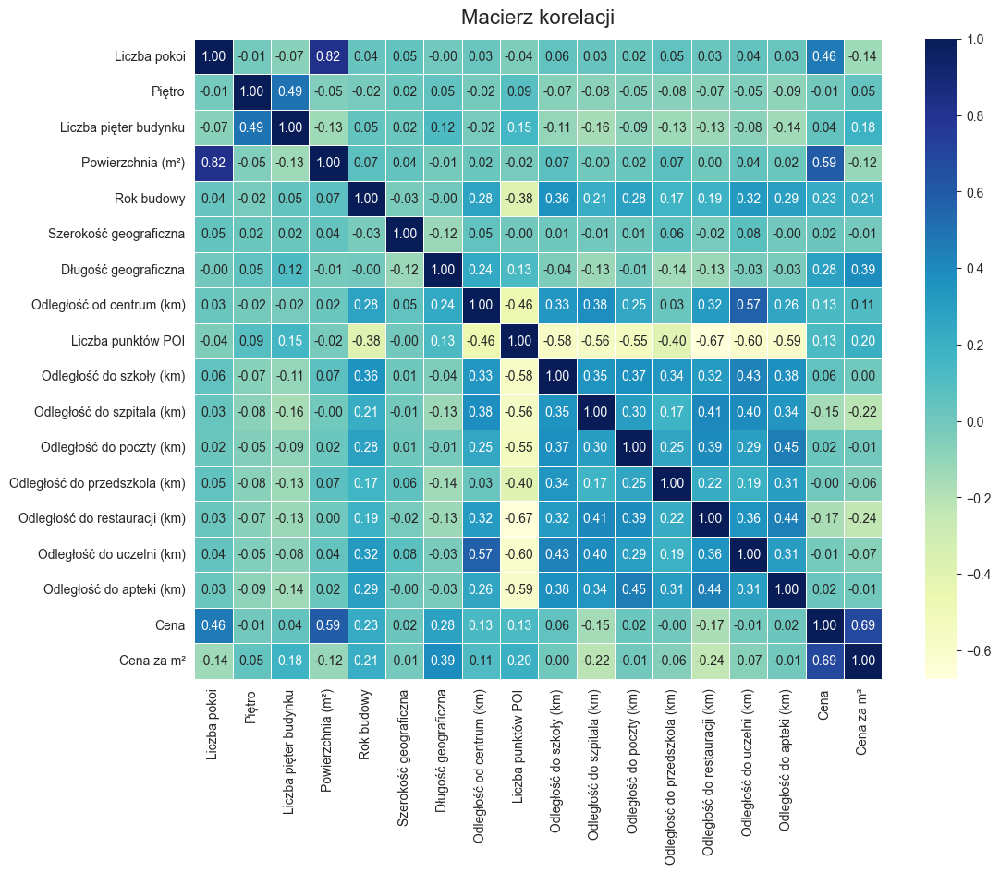

In [9]:
generate_correlation_heatmap(df, both_categorical_and_numeric + numeric_data)

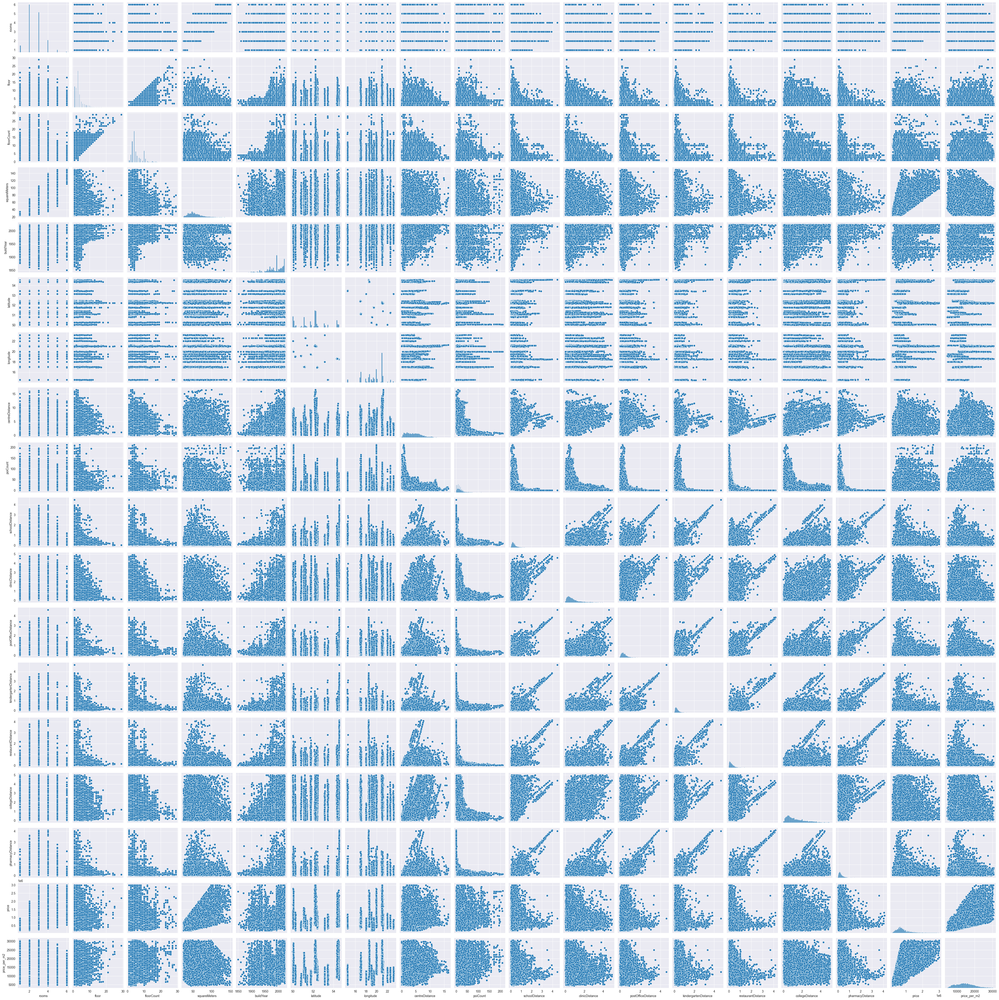

In [10]:
sns.pairplot(df[both_categorical_and_numeric + numeric_data])
plt.show()

In [9]:
alpha = 0.05

result_df = corr_test(df=df, column_list=numeric_data+both_categorical_and_numeric, column="price_per_m2")

result_df = result_df.style.apply(lambda x: ['background-color: red' if p > alpha else '' for p in x],
                                  subset=[('Pearson', 'p-wartość'), ('Spearman', 'p-wartość')]).set_caption(r'Wyniki testu korelacji dla kolumny "Cena za $m^2$"')
result_df = result_df.background_gradient(axis=None, cmap="Reds", subset=[('Pearson', 'statystyka'), ('Spearman', 'statystyka')])
# result_df.to_excel("Wyniki_testu_korelacji.xlsx", engine='xlsxwriter')
display(result_df)
print(result_df.to_latex(convert_css=True))

\begin{table}
\caption{Wyniki testu korelacji dla kolumny "Cena za $m^2$"}
\begin{tabular}{lrrrr}
 & \multicolumn{2}{r}{Pearson} & \multicolumn{2}{r}{Spearman} \\
 & statystyka & p-wartość & statystyka & p-wartość \\
squareMeters & {\cellcolor[HTML]{FEDECF}} \color[HTML]{000000} -0.068737 & 0.000000 & {\cellcolor[HTML]{FEE5D9}} \color[HTML]{000000} -0.118196 & 0.000000 \\
buildYear & {\cellcolor[HTML]{FCA588}} \color[HTML]{000000} 0.159326 & 0.000000 & {\cellcolor[HTML]{FC9777}} \color[HTML]{000000} 0.209621 & 0.000000 \\
latitude & {\cellcolor[HTML]{FDD1BE}} \color[HTML]{000000} -0.013253 & {\cellcolor{red}} 0.056743 & {\cellcolor[HTML]{FDD1BE}} \color[HTML]{000000} -0.014040 & 0.043549 \\
longitude & {\cellcolor[HTML]{FB7555}} \color[HTML]{F1F1F1} 0.343161 & 0.000000 & {\cellcolor[HTML]{FB694A}} \color[HTML]{F1F1F1} 0.387312 & 0.000000 \\
centreDistance & {\cellcolor[HTML]{FCB89E}} \color[HTML]{000000} 0.084527 & 0.000000 & {\cellcolor[HTML]{FCB095}} \color[HTML]{000000} 0.115777 & 0

In [10]:
result_df = corr_test(df=df, column_list=numeric_data+both_categorical_and_numeric, column="price")

result_df = result_df.style.apply(lambda x: ['background-color: red' if p > alpha else '' for p in x],
                                  subset=[('Pearson', 'p-wartość'), ('Spearman', 'p-wartość')]).set_caption('Wyniki testu korelacji dla kolumny "Cena"')
result_df = result_df.background_gradient(axis=None, cmap="Reds", subset=[('Pearson', 'statystyka'), ('Spearman', 'statystyka')])
result_df

In [11]:
for city, table in city_dataframes.items():
    table = table.select_dtypes(include='number')
    columns = table.columns
    columns = columns.drop("price")
    table = smart_imputer(table)[0]
    try:
        result_df = corr_test(df=table, column_list=columns, column="price_per_m2")
        result_df = result_df.style.apply(lambda x: ['background-color: red' if p > alpha else '' for p in x],
                                          subset=[('Pearson', 'p-wartość'), ('Spearman', 'p-wartość')]).set_caption(f'Wyniki testu korelacji dla miasta {city}, kolumny "Cena za m^2"')
        result_df = result_df.background_gradient(axis=None, cmap="Reds", subset=[('Pearson', 'statystyka'), ('Spearman', 'statystyka')])

        display(result_df)
        print(result_df.to_latex(convert_css=True))
    except Exception as e:
        columns = columns.drop("buildYear")
        result_df = corr_test(df=table, column_list=columns, column="price_per_m2")
        result_df = result_df.style.apply(lambda x: ['background-color: red' if p > alpha else '' for p in x],
                                          subset=[('Pearson', 'p-wartość'), ('Spearman', 'p-wartość')]).set_caption(f'Wyniki testu korelacji dla miasta {city}, kolumny "Cena za m^2"')
        result_df = result_df.background_gradient(axis=None, cmap="Reds", subset=[('Pearson', 'statystyka'), ('Spearman', 'statystyka')])

        # display(result_df)
        #
        # print(result_df.to_latex())

\begin{table}
\caption{Wyniki testu korelacji dla miasta Szczecin, kolumny "Cena za m^2"}
\begin{tabular}{lrrrr}
 & \multicolumn{2}{r}{Pearson} & \multicolumn{2}{r}{Spearman} \\
 & statystyka & p-wartość & statystyka & p-wartość \\
squareMeters & {\cellcolor[HTML]{FFF1EA}} \color[HTML]{000000} -0.567324 & 0.000000 & {\cellcolor[HTML]{FFF5F0}} \color[HTML]{000000} -0.605636 & 0.000000 \\
rooms & {\cellcolor[HTML]{FEE5D9}} \color[HTML]{000000} -0.454798 & 0.000000 & {\cellcolor[HTML]{FEE5D9}} \color[HTML]{000000} -0.453875 & 0.000000 \\
floor & {\cellcolor[HTML]{FC9373}} \color[HTML]{000000} -0.005931 & {\cellcolor{red}} 0.880872 & {\cellcolor[HTML]{FCA183}} \color[HTML]{000000} -0.074079 & {\cellcolor{red}} 0.060869 \\
floorCount & {\cellcolor[HTML]{FA6648}} \color[HTML]{F1F1F1} 0.211510 & 0.000000 & {\cellcolor[HTML]{FB7656}} \color[HTML]{F1F1F1} 0.137585 & 0.000477 \\
buildYear & {\cellcolor[HTML]{CF1C1F}} \color[HTML]{F1F1F1} 0.577069 & 0.000000 & {\cellcolor[HTML]{D01D1F}} \color[HT

\begin{table}
\caption{Wyniki testu korelacji dla miasta Gdynia, kolumny "Cena za m^2"}
\begin{tabular}{lrrrr}
 & \multicolumn{2}{r}{Pearson} & \multicolumn{2}{r}{Spearman} \\
 & statystyka & p-wartość & statystyka & p-wartość \\
squareMeters & {\cellcolor[HTML]{FCA78B}} \color[HTML]{000000} -0.020828 & {\cellcolor{red}} 0.570571 & {\cellcolor[HTML]{FCBBA1}} \color[HTML]{000000} -0.106957 & 0.003491 \\
rooms & {\cellcolor[HTML]{FCC3AB}} \color[HTML]{000000} -0.145511 & 0.000068 & {\cellcolor[HTML]{FDC7B2}} \color[HTML]{000000} -0.168662 & 0.000004 \\
floor & {\cellcolor[HTML]{FC8A6A}} \color[HTML]{F1F1F1} 0.113611 & 0.001911 & {\cellcolor[HTML]{FCA082}} \color[HTML]{000000} 0.018040 & {\cellcolor{red}} 0.623226 \\
floorCount & {\cellcolor[HTML]{FB6C4C}} \color[HTML]{F1F1F1} 0.251466 & 0.000000 & {\cellcolor[HTML]{FC8D6D}} \color[HTML]{F1F1F1} 0.103946 & 0.004537 \\
buildYear & {\cellcolor[HTML]{FB6B4B}} \color[HTML]{F1F1F1} 0.257873 & 0.000000 & {\cellcolor[HTML]{FB6E4E}} \color[HTML]{

\begin{table}
\caption{Wyniki testu korelacji dla miasta Kraków, kolumny "Cena za m^2"}
\begin{tabular}{lrrrr}
 & \multicolumn{2}{r}{Pearson} & \multicolumn{2}{r}{Spearman} \\
 & statystyka & p-wartość & statystyka & p-wartość \\
squareMeters & {\cellcolor[HTML]{FCA98C}} \color[HTML]{000000} -0.080618 & 0.000005 & {\cellcolor[HTML]{FCBBA1}} \color[HTML]{000000} -0.164049 & 0.000000 \\
rooms & {\cellcolor[HTML]{FCB89E}} \color[HTML]{000000} -0.150691 & 0.000000 & {\cellcolor[HTML]{FCBEA5}} \color[HTML]{000000} -0.180469 & 0.000000 \\
floor & {\cellcolor[HTML]{FC9C7D}} \color[HTML]{000000} -0.018898 & {\cellcolor{red}} 0.286345 & {\cellcolor[HTML]{FC9E80}} \color[HTML]{000000} -0.029756 & {\cellcolor{red}} 0.093144 \\
floorCount & {\cellcolor[HTML]{FC9777}} \color[HTML]{000000} 0.003506 & {\cellcolor{red}} 0.843198 & {\cellcolor[HTML]{FC8A6A}} \color[HTML]{F1F1F1} 0.064673 & 0.000260 \\
buildYear & {\cellcolor[HTML]{FC9373}} \color[HTML]{000000} 0.022370 & {\cellcolor{red}} 0.206900 & {\

\begin{table}
\caption{Wyniki testu korelacji dla miasta Poznań, kolumny "Cena za m^2"}
\begin{tabular}{lrrrr}
 & \multicolumn{2}{r}{Pearson} & \multicolumn{2}{r}{Spearman} \\
 & statystyka & p-wartość & statystyka & p-wartość \\
squareMeters & {\cellcolor[HTML]{FFF1EA}} \color[HTML]{000000} -0.381816 & 0.000000 & {\cellcolor[HTML]{FFF5F0}} \color[HTML]{000000} -0.418918 & 0.000000 \\
rooms & {\cellcolor[HTML]{FFEEE6}} \color[HTML]{000000} -0.354770 & 0.000000 & {\cellcolor[HTML]{FFEFE8}} \color[HTML]{000000} -0.368189 & 0.000000 \\
floor & {\cellcolor[HTML]{FCBDA4}} \color[HTML]{000000} -0.072560 & 0.044548 & {\cellcolor[HTML]{FCAE92}} \color[HTML]{000000} -0.007068 & {\cellcolor{red}} 0.845056 \\
floorCount & {\cellcolor[HTML]{FCBBA1}} \color[HTML]{000000} -0.063991 & {\cellcolor{red}} 0.076537 & {\cellcolor[HTML]{FC9474}} \color[HTML]{000000} 0.106230 & 0.003224 \\
buildYear & {\cellcolor[HTML]{FB6B4B}} \color[HTML]{F1F1F1} 0.285204 & 0.000000 & {\cellcolor[HTML]{F44D38}} \color[HTM

\begin{table}
\caption{Wyniki testu korelacji dla miasta Białystok, kolumny "Cena za m^2"}
\begin{tabular}{lrrrr}
 & \multicolumn{2}{r}{Pearson} & \multicolumn{2}{r}{Spearman} \\
 & statystyka & p-wartość & statystyka & p-wartość \\
squareMeters & {\cellcolor[HTML]{FFF5F0}} \color[HTML]{000000} -0.417871 & 0.000000 & {\cellcolor[HTML]{FFF4EE}} \color[HTML]{000000} -0.401733 & 0.000000 \\
rooms & {\cellcolor[HTML]{FFECE3}} \color[HTML]{000000} -0.340134 & 0.000000 & {\cellcolor[HTML]{FEEAE0}} \color[HTML]{000000} -0.322497 & 0.000001 \\
floor & {\cellcolor[HTML]{FCA588}} \color[HTML]{000000} 0.033758 & {\cellcolor{red}} 0.611315 & {\cellcolor[HTML]{FCA486}} \color[HTML]{000000} 0.037171 & {\cellcolor{red}} 0.575747 \\
floorCount & {\cellcolor[HTML]{FB7C5C}} \color[HTML]{F1F1F1} 0.208533 & 0.001507 & {\cellcolor[HTML]{FC9576}} \color[HTML]{000000} 0.098890 & {\cellcolor{red}} 0.135712 \\
buildYear & {\cellcolor[HTML]{F14432}} \color[HTML]{F1F1F1} 0.431294 & 0.000000 & {\cellcolor[HTML]{F

...

/Users/zuzannasosnowska/PycharmProjects/UniversityProjects/Semestr 7/Praca_inżynierska/functions.py:103: UserWarning: Kolumna "buildYear" ma >40% braków → NIE imputuję.
  warnings.warn(f'Kolumna "{column}" ma >40% braków → NIE imputuję.')


\begin{table}
\caption{Wyniki testu korelacji dla miasta Lublin, kolumny "Cena za m^2"}
\begin{tabular}{lrrrr}
 & \multicolumn{2}{r}{Pearson} & \multicolumn{2}{r}{Spearman} \\
 & statystyka & p-wartość & statystyka & p-wartość \\
squareMeters & {\cellcolor[HTML]{FFF5F0}} \color[HTML]{000000} -0.406351 & 0.000000 & {\cellcolor[HTML]{FFF5F0}} \color[HTML]{000000} -0.403776 & 0.000000 \\
rooms & {\cellcolor[HTML]{FFF3ED}} \color[HTML]{000000} -0.386645 & 0.000000 & {\cellcolor[HTML]{FFF4EE}} \color[HTML]{000000} -0.391597 & 0.000000 \\
floor & {\cellcolor[HTML]{FDD3C1}} \color[HTML]{000000} -0.168647 & 0.000110 & {\cellcolor[HTML]{FDD5C4}} \color[HTML]{000000} -0.177461 & 0.000046 \\
floorCount & {\cellcolor[HTML]{FCB79C}} \color[HTML]{000000} -0.036054 & {\cellcolor{red}} 0.411517 & {\cellcolor[HTML]{FCAB8F}} \color[HTML]{000000} 0.013618 & {\cellcolor{red}} 0.756479 \\
buildYear & {\cellcolor[HTML]{F6583E}} \color[HTML]{F1F1F1} 0.365394 & 0.000000 & {\cellcolor[HTML]{F34935}} \color[HTM

/Users/zuzannasosnowska/PycharmProjects/UniversityProjects/Semestr 7/Praca_inżynierska/functions.py:103: UserWarning: Kolumna "buildYear" ma >40% braków → NIE imputuję.
  warnings.warn(f'Kolumna "{column}" ma >40% braków → NIE imputuję.')


\begin{table}
\caption{Wyniki testu korelacji dla miasta Warszawa, kolumny "Cena za m^2"}
\begin{tabular}{lrrrr}
 & \multicolumn{2}{r}{Pearson} & \multicolumn{2}{r}{Spearman} \\
 & statystyka & p-wartość & statystyka & p-wartość \\
squareMeters & {\cellcolor[HTML]{FCB499}} \color[HTML]{000000} -0.077352 & 0.000000 & {\cellcolor[HTML]{FDC6B0}} \color[HTML]{000000} -0.166664 & 0.000000 \\
rooms & {\cellcolor[HTML]{FDCAB5}} \color[HTML]{000000} -0.180076 & 0.000000 & {\cellcolor[HTML]{FDD3C1}} \color[HTML]{000000} -0.228665 & 0.000000 \\
floor & {\cellcolor[HTML]{FC9879}} \color[HTML]{000000} 0.052305 & 0.000043 & {\cellcolor[HTML]{FCA183}} \color[HTML]{000000} 0.009668 & {\cellcolor{red}} 0.449723 \\
floorCount & {\cellcolor[HTML]{FC9373}} \color[HTML]{000000} 0.074320 & 0.000000 & {\cellcolor[HTML]{FC9373}} \color[HTML]{000000} 0.073545 & 0.000000 \\
buildYear & {\cellcolor[HTML]{FCAA8D}} \color[HTML]{000000} -0.032637 & 0.010701 & {\cellcolor[HTML]{FC9D7F}} \color[HTML]{000000} 0.02705

\begin{table}
\caption{Wyniki testu korelacji dla miasta Bydgoszcz, kolumny "Cena za m^2"}
\begin{tabular}{lrrrr}
 & \multicolumn{2}{r}{Pearson} & \multicolumn{2}{r}{Spearman} \\
 & statystyka & p-wartość & statystyka & p-wartość \\
squareMeters & {\cellcolor[HTML]{FFF5F0}} \color[HTML]{000000} -0.292589 & 0.000000 & {\cellcolor[HTML]{FFF1EA}} \color[HTML]{000000} -0.257774 & 0.000000 \\
rooms & {\cellcolor[HTML]{FEE2D5}} \color[HTML]{000000} -0.141995 & 0.000016 & {\cellcolor[HTML]{FEE1D4}} \color[HTML]{000000} -0.140789 & 0.000019 \\
floor & {\cellcolor[HTML]{FDC5AE}} \color[HTML]{000000} -0.013637 & {\cellcolor{red}} 0.680202 & {\cellcolor[HTML]{FDC5AE}} \color[HTML]{000000} -0.010667 & {\cellcolor{red}} 0.747139 \\
floorCount & {\cellcolor[HTML]{FCA98C}} \color[HTML]{000000} 0.106188 & 0.001288 & {\cellcolor[HTML]{FCA183}} \color[HTML]{000000} 0.135933 & 0.000037 \\
buildYear & {\cellcolor[HTML]{000000}} \color[HTML]{F1F1F1} nan & nan & {\cellcolor[HTML]{000000}} \color[HTML]{F1F1F

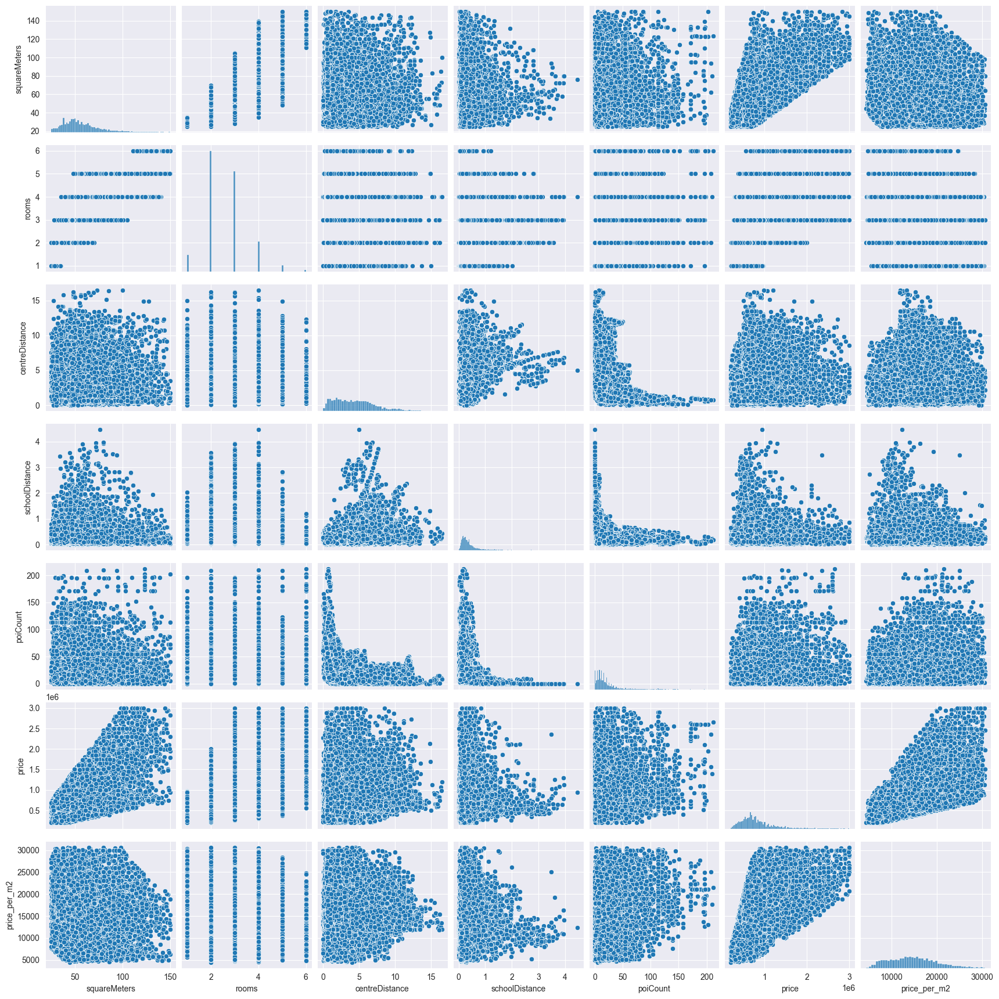

In [12]:
sns.pairplot(df[["squareMeters", "rooms", "centreDistance", "schoolDistance", "poiCount", "price", "price_per_m2"]])
plt.show()